# 09e · Stereoscope deconvolution results — review

Companion to `09b` (cell2location run 3), for the stereoscope run (`utils/run_deconv_stereoscope.py`, scvi-tools, run on the Tailscale peer 2026-10-22: 400 reference + 2000 spatial epochs; proportions extracted 2026-10-23 with `STEREO_RESUME=1`).
Same reference (6 Linnarsson brain classes + `MYE:Microglia`) and the same 11,264 genes as c2l run 3.
Reads only the small local artifacts in `results/tables/deconvolution_stereoscope/` and `results/figures/manuscript/deconv_stereo_*`. **No compute is needed.**

Fractions are **renormalized over the real cell types** after dropping stereoscope's per-spot noise term (section 5), so they're comparable to c2l fractions.
For the head-to-head comparison with cell2location, see `09d`.

In [1]:
%matplotlib inline
import pandas as pd, numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib import image as mpimg
from scipy.stats import mannwhitneyu

ROOT = Path.cwd()
while not (ROOT / 'results').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
TBL = ROOT / 'results' / 'tables' / 'deconvolution_stereoscope'
FIG = ROOT / 'results' / 'figures' / 'manuscript'
SCORES_CSV = ROOT / 'results' / 'inflammation' / 'tables' / 'per_spot_scores.csv'   # spot -> section / treatment / region

frac  = pd.read_csv(TBL / 'per_spot_fractions.csv', index_col=0)
noise = pd.read_csv(TBL / 'noise_fraction.csv', index_col=0).iloc[:, 0]
comp  = pd.read_csv(TBL / 'region_treatment_composition.csv')
meta  = pd.read_csv(SCORES_CSV, index_col=0, usecols=[0, 1, 2, 3]).reindex(frac.index)
meta['slide'] = meta['sample_id'].str.split('_').str[0]

MYE = [c for c in frac.columns if c.startswith('MYE:')]
STRUCT = [c for c in frac.columns if not c.startswith('MYE:')]
REG, TREAT = 're_annotation_regions', 'treatment'
order = ['WT', 'PBS', 'BRICHOS']
palette = {'WT': '#7570b3', 'PBS': '#d95f02', 'BRICHOS': '#1b9e77'}
print(f'{frac.shape[0]:,} spots x {frac.shape[1]} cell types')
print('structural:', STRUCT)
print('immune    :', MYE)

25,660 spots x 7 cell types
structural: ['Astrocytes', 'Ependymal', 'Neurons', 'Oligos', 'PeripheralGlia', 'Vascular']
immune    : ['MYE:Microglia']


## 1 · Training convergence

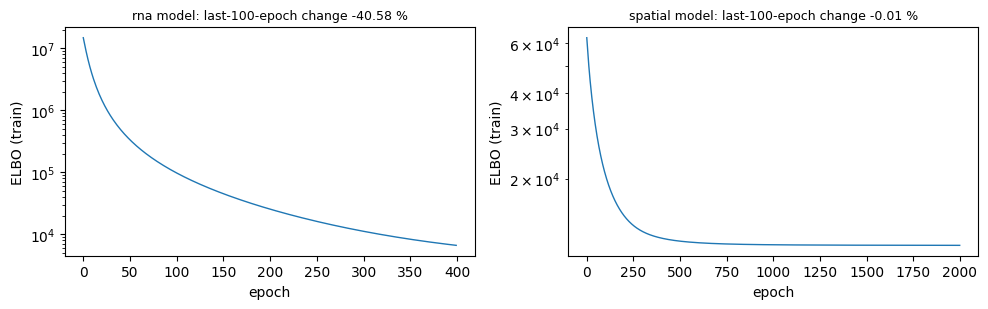

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, name in zip(axes, ['rna', 'spatial']):
    h = pd.read_csv(TBL / f'loss_{name}.csv', index_col=0).iloc[:, 0]
    ax.plot(h.index, h.values, lw=1)
    ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.set_ylabel('ELBO (train)')
    tail = h.iloc[-100:]
    ax.set_title(f'{name} model: last-100-epoch change {100 * (tail.iloc[-1] / tail.iloc[0] - 1):+.2f} %', fontsize=9)
plt.tight_layout(); plt.show()

## 2 · Overall composition (all spots)

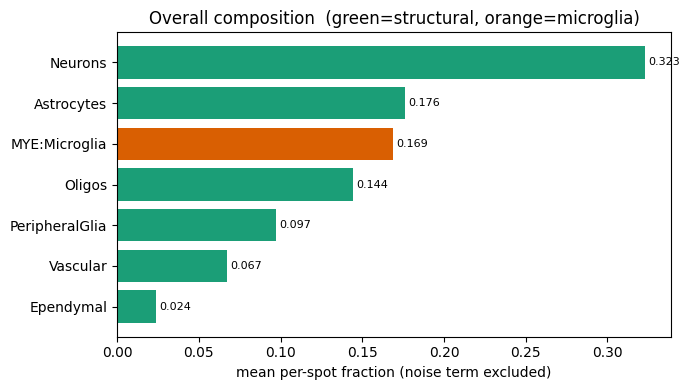

microglia     = 0.169  (c2l run 3: ~0.10)
total struct  = 0.831
noise term    = 0.314 of each spot before renormalization


In [3]:
mean = frac.mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
colors = ['#d95f02' if c.startswith('MYE:') else '#1b9e77' for c in mean.index]
ax.barh(mean.index[::-1], mean.values[::-1], color=colors[::-1])
ax.set_xlabel('mean per-spot fraction (noise term excluded)')
ax.set_title('Overall composition  (green=structural, orange=microglia)')
for i, v in enumerate(mean.values[::-1]):
    ax.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=8)
plt.tight_layout(); plt.show()

print(f"microglia     = {frac[MYE].sum(axis=1).mean():.3f}  (c2l run 3: ~0.10)")
print(f"total struct  = {frac[STRUCT].sum(axis=1).mean():.3f}")
print(f"noise term    = {noise.mean():.3f} of each spot before renormalization")

## 3 · Composition by region × treatment
Region rows = mean fraction over all spots of that region and treatment.

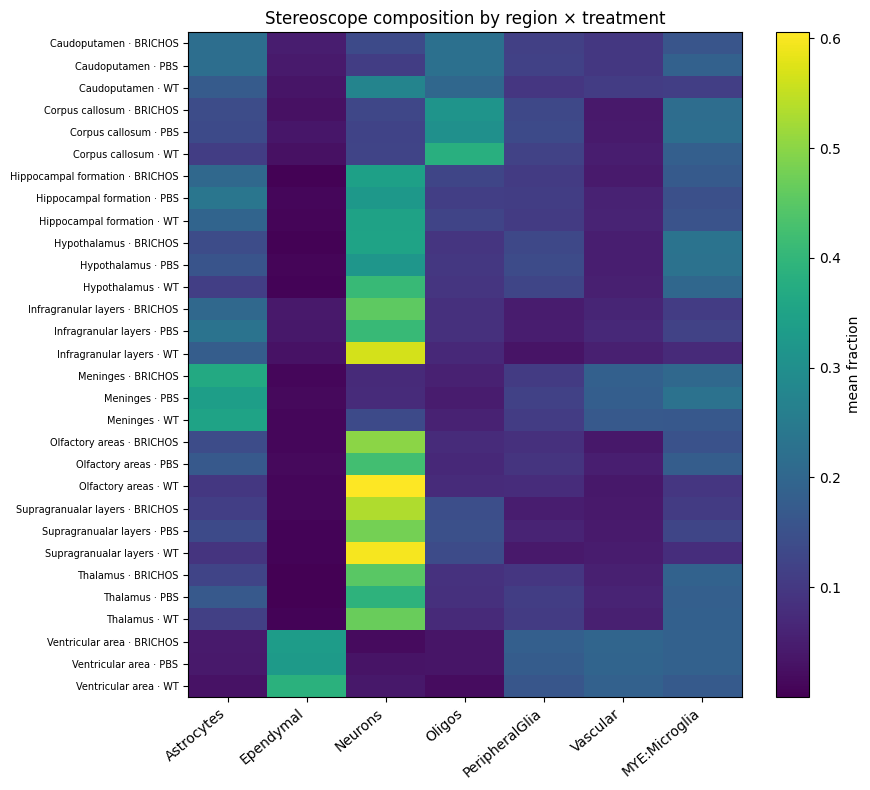

In [4]:
piv = comp.set_index([REG, TREAT])[STRUCT + MYE]
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(piv.values, aspect='auto', cmap='viridis')
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns, rotation=40, ha='right')
ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels([f'{r} · {t}' for r, t in piv.index], fontsize=7)
fig.colorbar(im, ax=ax, label='mean fraction'); ax.set_title('Stereoscope composition by region × treatment')
plt.tight_layout(); plt.show()

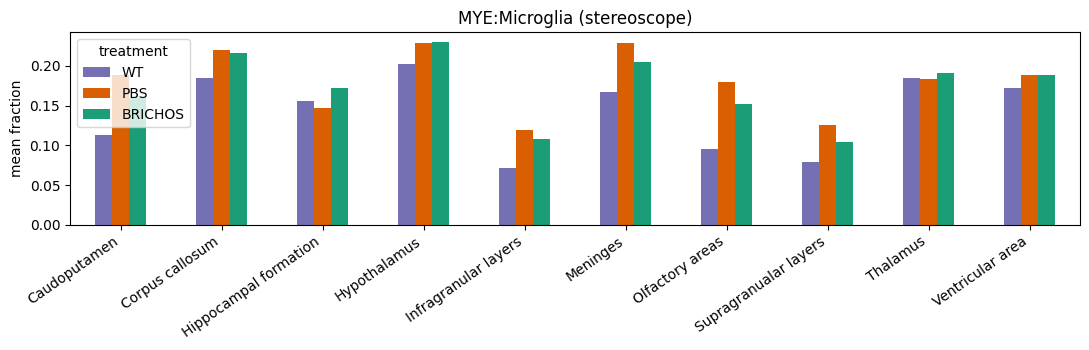

In [5]:
p = comp.pivot(index=REG, columns=TREAT, values='MYE:Microglia')[order]
ax = p.plot(kind='bar', figsize=(11, 3.6), color=[palette[t] for t in order])
ax.set_title('MYE:Microglia (stereoscope)'); ax.set_ylabel('mean fraction'); ax.set_xlabel('')
plt.xticks(rotation=35, ha='right'); plt.tight_layout(); plt.show()

## 4 · BRICHOS − PBS shift by region
Unlike 09b, the test here uses **section means**: a per-section mean in each region, then Mann-Whitney between PBS (6 sections) and BRICHOS (3). Regions not present in every section have fewer sections. Negative delta = BRICHOS lower than PBS. The slide colour shows the confound: all PBS sections are on P28052, and BRICHOS 201/301 are on P24215.

,region,n_pbs,n_bri,mean_pbs,mean_bri,delta,pct,mwu_p
0,Caudoputamen,6,3,0.1854,0.1582,-0.0273,-14.7042,0.2619
4,Meninges,6,3,0.2284,0.2057,-0.0227,-9.9268,0.0476
6,Supragranualar layers,6,3,0.1245,0.1050,-0.0196,-15.7222,0.2619
5,Olfactory areas,6,3,0.1736,0.1546,-0.0190,-10.9331,0.7143
3,Infragranular layers,6,3,0.1181,0.1075,-0.0106,-8.9591,0.2619
2,Hypothalamus,6,3,0.2335,0.2322,-0.0013,-0.5735,1.0000
1,Corpus callosum,6,3,0.2127,0.2141,0.0014,0.6649,0.9048


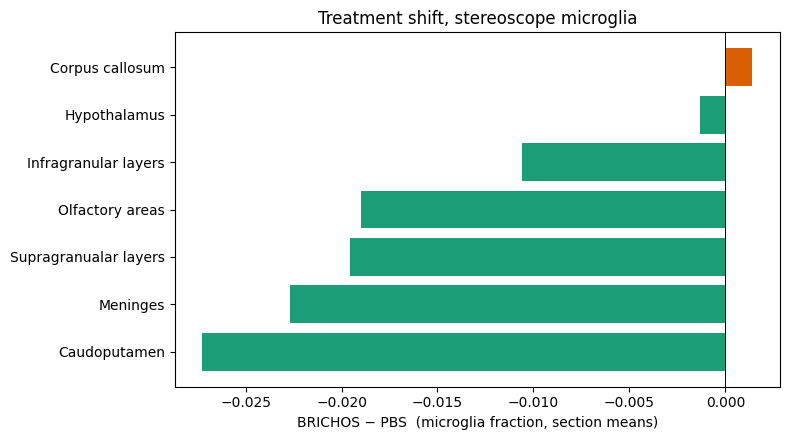

In [6]:
d = frac[MYE].join(meta)
sec = d.groupby(['sample_id', TREAT, 'slide', REG], observed=True)[MYE[0]].agg(['mean', 'size']).reset_index()
sec = sec[sec['size'] >= 30]

rows = []
for r, g in sec.groupby(REG):
    x = g.loc[g[TREAT] == 'PBS', 'mean']; z = g.loc[g[TREAT] == 'BRICHOS', 'mean']
    if len(x) < 2 or len(z) < 2:
        continue
    rows.append(dict(region=r, n_pbs=len(x), n_bri=len(z), mean_pbs=x.mean(), mean_bri=z.mean(),
                     delta=z.mean() - x.mean(), pct=100 * (z.mean() / x.mean() - 1), mwu_p=mannwhitneyu(x, z).pvalue))
shift = pd.DataFrame(rows).sort_values('delta')
shift.to_csv(TBL / 'microglia_BRIvPBS_shift_sections.csv', index=False)
display(shift.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(shift['region'], shift['delta'], color=np.where(shift['delta'] < 0, '#1b9e77', '#d95f02'))
ax.axvline(0, color='k', lw=.7); ax.set_xlabel('BRICHOS − PBS  (microglia fraction, section means)')
ax.set_title('Treatment shift, stereoscope microglia'); plt.tight_layout(); plt.show()

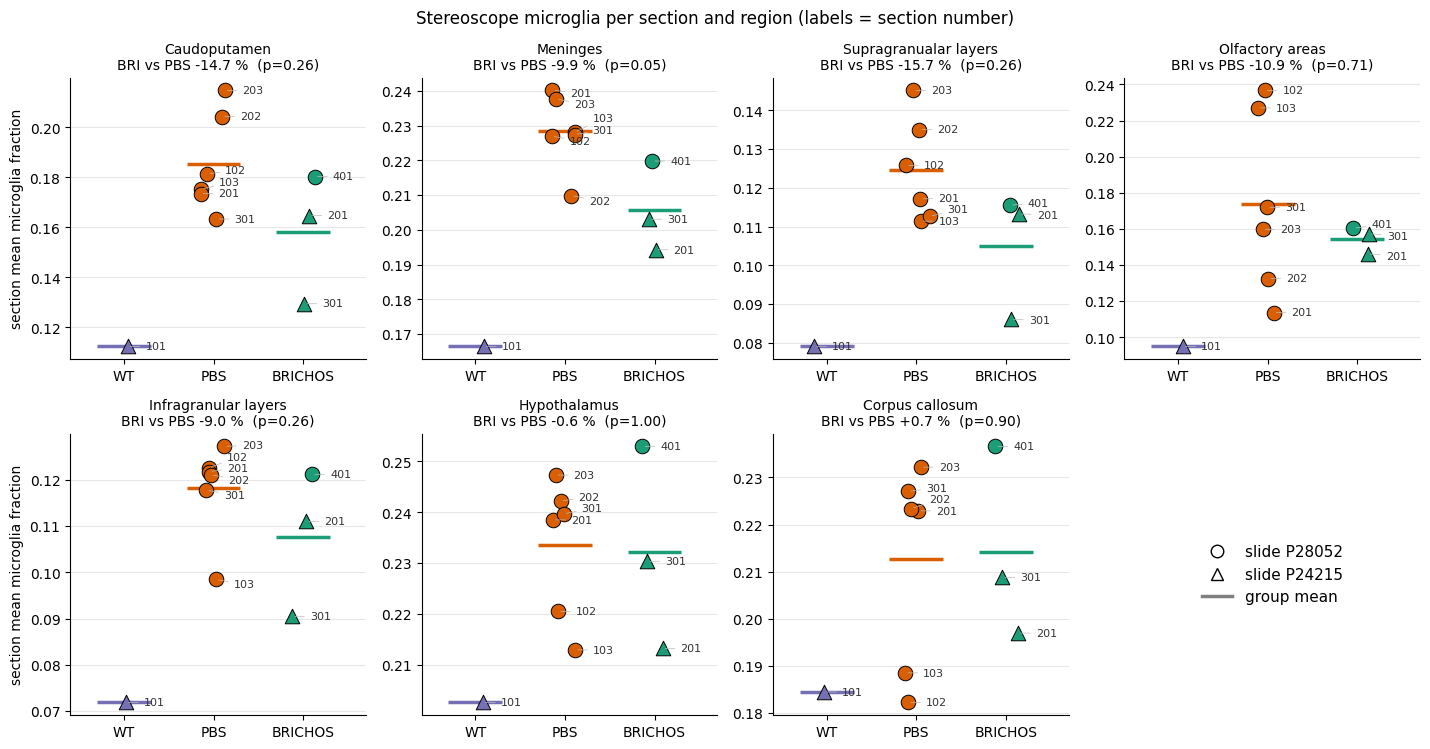

In [7]:
# per-section view: is the shift carried by the P24215 BRICHOS sections?
from matplotlib.lines import Line2D
regions = shift['region'].tolist()
ncol = 4
nrow = int(np.ceil(len(regions) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.8 * nrow))
MARK = {'P28052': 'o', 'P24215': '^'}
rng = np.random.default_rng(0)
def label_points(ax, xs, ys, labels, x_off=.2, min_gap=.045):
    """Section labels to the right of the points, nudged apart vertically (min_gap = fraction of y-range)."""
    lo, hi = sec.loc[sec[REG] == r, 'mean'].agg(['min', 'max'])
    gap = min_gap * (hi - lo)
    idx = np.argsort(ys)
    ly = np.array(ys, dtype=float)[idx]
    for k in range(1, len(ly)):
        ly[k] = max(ly[k], ly[k - 1] + gap)
    ly -= (ly.mean() - np.mean(np.array(ys)[idx])) if len(ly) > 1 and ly[-1] > max(ys) else 0
    for (x, y), lab, yy in zip(np.c_[xs, ys][idx], np.array(labels)[idx], ly):
        ax.annotate(lab, (x, y), xytext=(x + x_off, yy), textcoords='data', fontsize=8, va='center',
                    color='#333', arrowprops=dict(arrowstyle='-', color='#bbb', lw=.5))

for ax, r in zip(axes.flat, regions):
    g = sec[sec[REG] == r]
    for i, t in enumerate(order):
        gg = g[g[TREAT] == t]
        if gg.empty:
            continue
        xj = i + rng.uniform(-.15, .15, len(gg))
        for sl, mk in MARK.items():
            m = (gg['slide'] == sl).values
            ax.scatter(xj[m], gg['mean'].values[m], marker=mk, s=110, c=palette[t],
                       edgecolor='k', lw=.7, zorder=3)
        label_points(ax, xj, gg['mean'].values, gg['sample_id'].str.split('_').str[1].values)
        ax.hlines(gg['mean'].mean(), i - .3, i + .3, color=palette[t], lw=2.5, zorder=2)
    row_ = shift.set_index('region').loc[r]
    ax.set_title(f"{r}\nBRI vs PBS {row_['pct']:+.1f} %  (p={row_['mwu_p']:.2f})", fontsize=10)
    ax.set_xticks(range(3)); ax.set_xticklabels(order, fontsize=10)
    ax.set_xlim(-.6, 2.7)
    ax.grid(axis='y', alpha=.3)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
for ax in axes.flat[len(regions):]:
    ax.axis('off')
for ax in axes[:, 0]:
    ax.set_ylabel('section mean microglia fraction')
handles = [Line2D([], [], marker='o', ls='', mfc='w', mec='k', ms=9, label='slide P28052'),
           Line2D([], [], marker='^', ls='', mfc='w', mec='k', ms=9, label='slide P24215'),
           Line2D([], [], color='grey', lw=2.5, label='group mean')]
axes.flat[-1].legend(handles=handles, loc='center', frameon=False, fontsize=11)
fig.suptitle('Stereoscope microglia per section and region (labels = section number)', fontsize=12)
plt.tight_layout()
fig.savefig(FIG / 'deconv_stereo_microglia_per_section_regions.png', dpi=200, bbox_inches='tight')
plt.show()


## 5 · Noise term
Stereoscope fits a per-gene "noise cell type" that absorbs ambient/unexplained signal. It is dropped before renormalization, so where it is large the remaining fractions (and relative differences between them) are stretched.

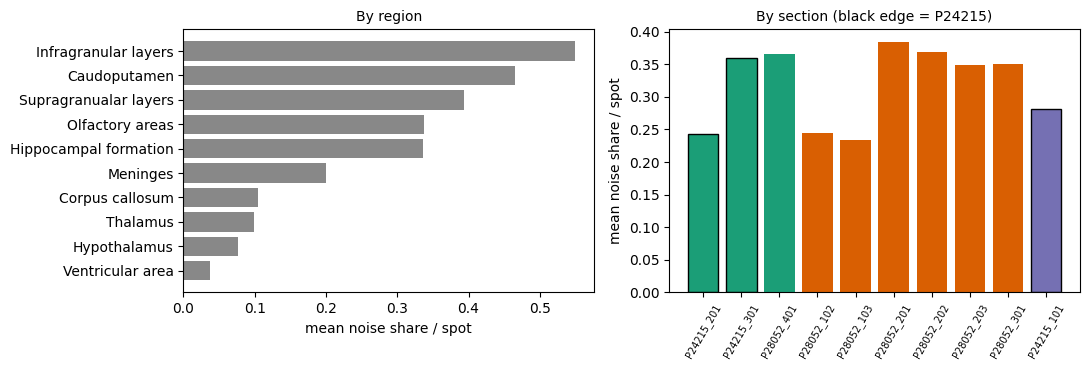

In [8]:
dn = meta.assign(noise=noise.reindex(meta.index).values)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
r = dn.groupby(REG, observed=True)['noise'].mean().sort_values()
axes[0].barh(r.index, r.values, color='#888'); axes[0].set_xlabel('mean noise share / spot'); axes[0].set_title('By region', fontsize=10)
s = dn.groupby(['sample_id', TREAT, 'slide'], observed=True)['noise'].mean().reset_index().sort_values([TREAT, 'sample_id'])
axes[1].bar(s['sample_id'], s['noise'], color=[palette[t] for t in s[TREAT]],
            hatch=None, edgecolor=['k' if sl == 'P24215' else 'none' for sl in s['slide']])
axes[1].set_ylabel('mean noise share / spot'); axes[1].set_title('By section (black edge = P24215)', fontsize=10)
axes[1].tick_params(axis='x', rotation=60, labelsize=7)
plt.tight_layout(); plt.show()

## 6 · Spatial maps (rendered PNGs, from the peer run)

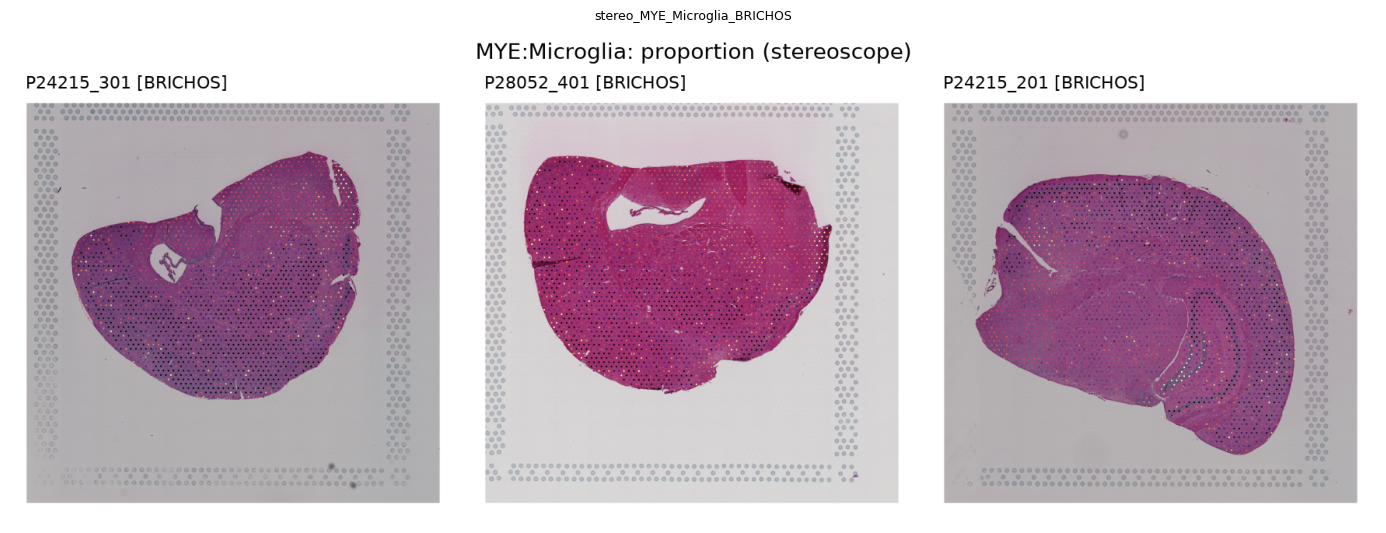

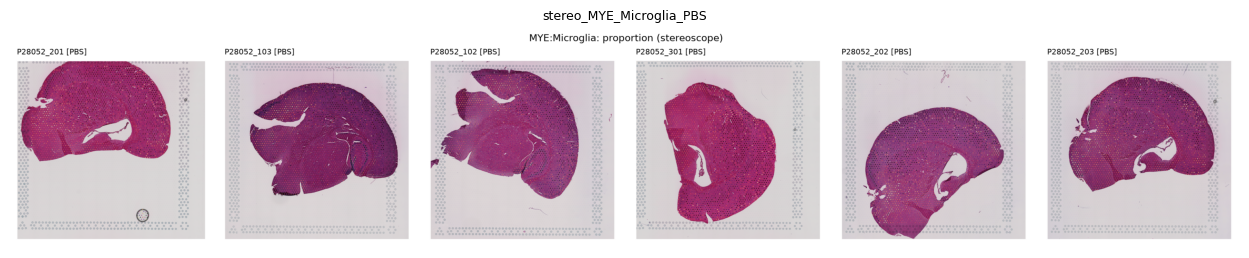

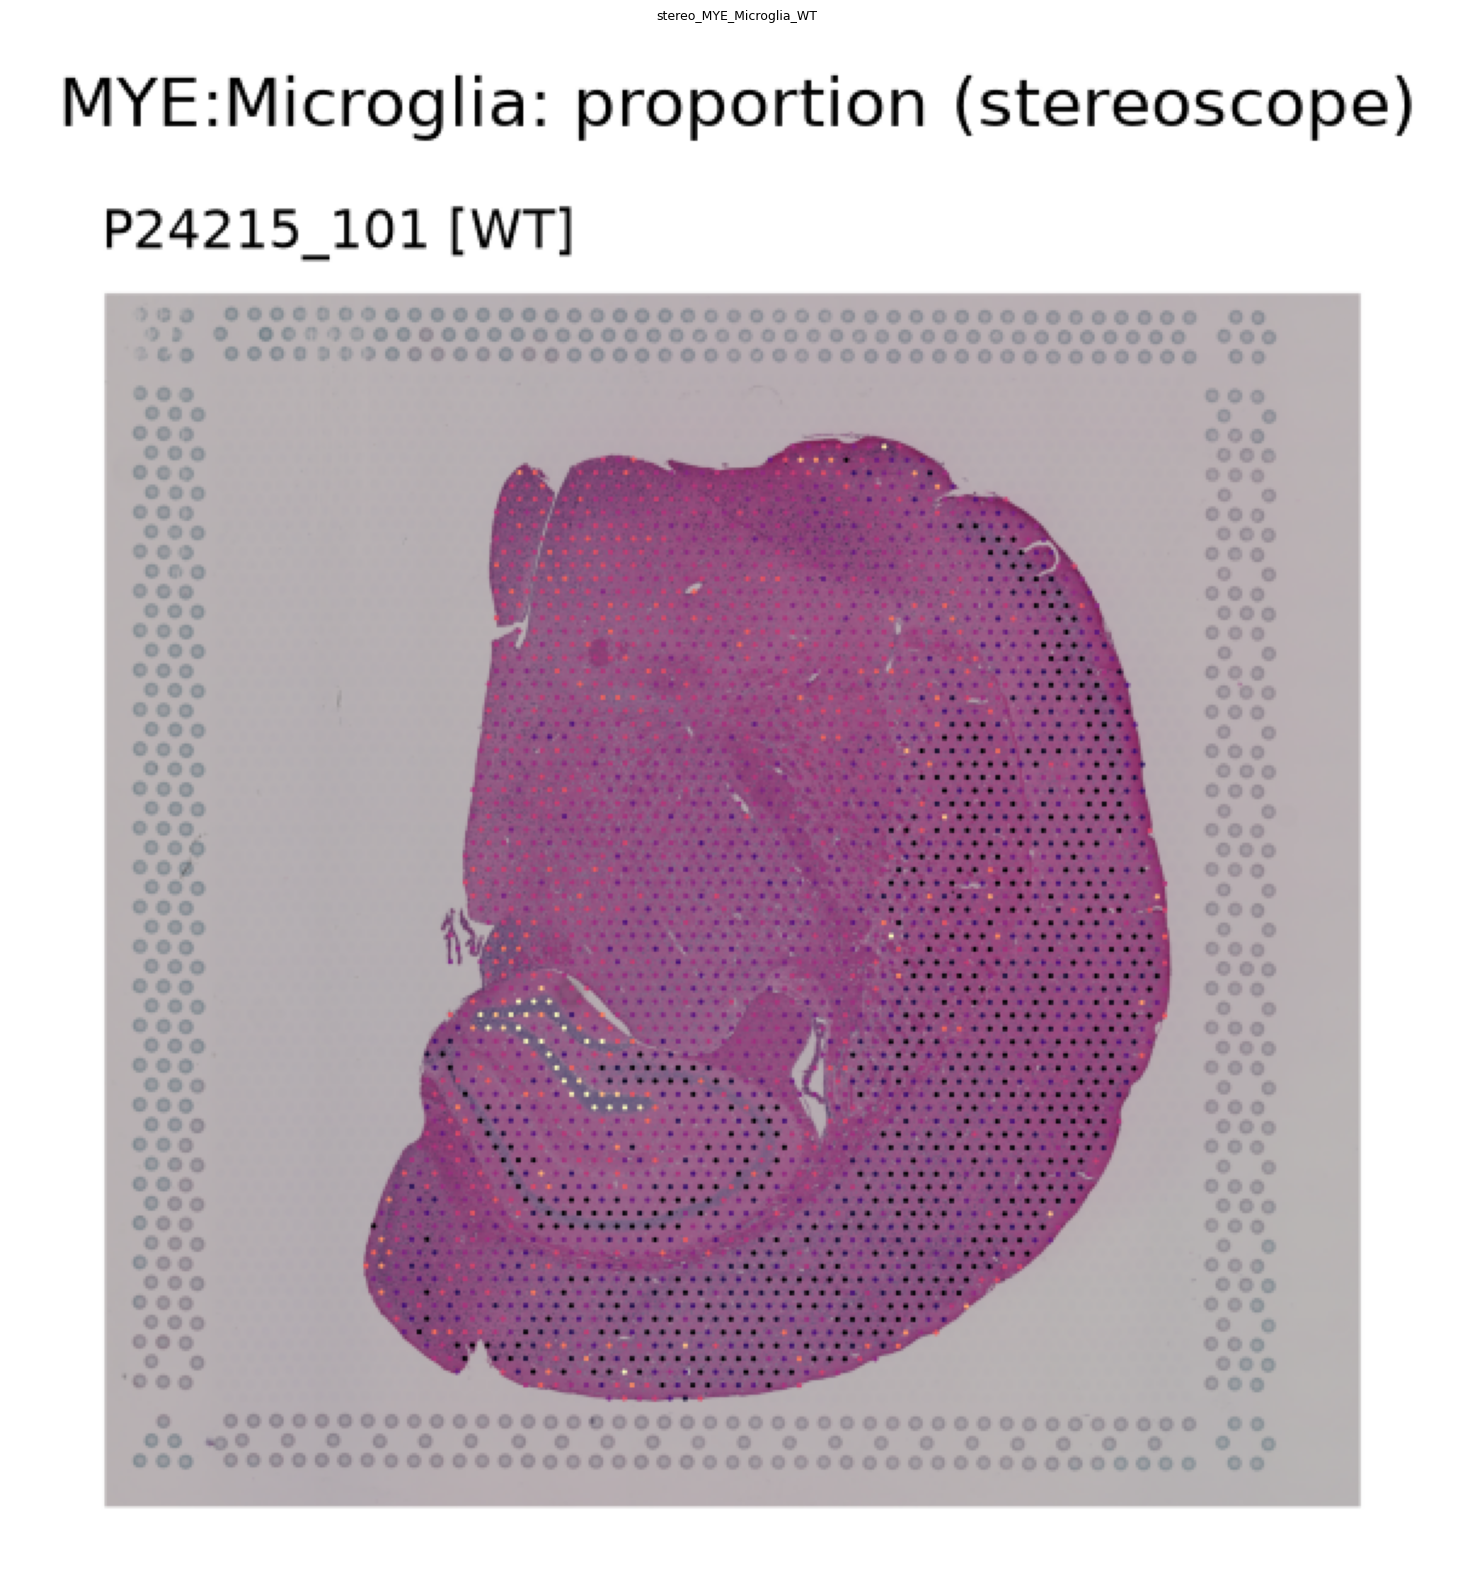

In [9]:
def show(pattern, ncol=1, w=15):
    files = sorted(FIG.glob(pattern))
    if not files:
        print('no files for', pattern); return
    for f in files:
        img = mpimg.imread(f)
        fig, ax = plt.subplots(figsize=(w, w * img.shape[0] / img.shape[1]))
        ax.imshow(img); ax.set_title(f.stem.replace('deconv_', ''), fontsize=9); ax.axis('off')
        plt.tight_layout(); plt.show()

show('deconv_stereo_MYE_Microglia_*.png')

## 7 · Caveats — read before quoting numbers

- **The reference (RNA) model had not converged at 400 epochs.** Its ELBO was still falling about 40 % over the last 100 epochs (§1), while the spatial model had plateaued (−0.01 %). The cell-type signatures are therefore not fully fitted. That may explain part of the gap to c2l (higher microglia, lower neurons, large noise term). A rerun with more reference epochs (e.g. `STEREO_SC_EPOCHS=2000`; it can't resume, because the spatial model is initialised from the reference) would settle it.

- **The absolute microglia fraction is not a cell count.** Stereoscope puts microglia at ~0.17/spot vs ~0.10 for c2l (and ~5 % expected), mostly at the expense of neurons. The noise term (~31 %/spot) is removed first and everything is rescaled. Use the *relative* pattern, not the level.
- **The noise share depends on region** (≈ 4–10 % in hypothalamus/thalamus/ventricles, ≈ 50 % in caudoputamen and infragranular cortex). Relative BRICHOS-vs-PBS differences in cortex and striatum are stretched by renormalization. Noise does not differ by slide or treatment (see `09d` §6).
- **The treatment shift is slide-confounded.** BRICHOS < PBS in most regions, carried by the two P24215 BRICHOS sections. BRICHOS 401, the only one on the PBS slide, sits within the PBS range. With slide in the model the effect goes to ~0 under both methods (`09d` §5: −7.8 % → +0.8 %).
- **Few replicates:** 6 PBS vs 3 BRICHOS sections, so the smallest possible MWU p is 0.024. Treat this as exploratory.
- **Agreement with c2l is moderate per spot** (microglia rho 0.48, hotspot Jaccard 0.55), but the region, treatment and downstream state-shift patterns all reproduce (`09d`).